# **Installing all the relavant libraries**

In [1]:
pip install pandas numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.



**Python Script: ECE Signal Telemetry Imputation Framework**

This experiment simulates an ECE scenario: a wireless sensor node transmitting packets containing Received Signal Strength Indicator (RSSI), Signal-to-Noise Ratio (SNR), and Bit Error Rate (BER). Random channel fades introduce missing samples (NaN), which we detect and resolve using ECE-specific methods.

In [2]:
import numpy as np
import pandas as pd
from sklearn.impute import KNNImputer

# 1. Simulate a Wireless Communication Link Dataset with missing data (packet drops)
communication_logs = {
    'Packet_ID': [101, 102, 103, 104, 105, 106, 107, 108],
    'RSSI_dBm':  [-72.5, -73.1, np.nan, -75.0, -78.4, np.nan, -71.2, -70.9],
    'SNR_dB':    [18.2, np.nan, 17.5, 15.1, np.nan, 16.8, 19.1, 19.5],
    'BER_e3':    [1.2, 1.4, 1.3, np.nan, 2.5, 2.1, np.nan, 1.1] # Bit Error Rate * 10^-3
}

df = pd.DataFrame(communication_logs).set_index('Packet_ID')
print("--- 1. Raw Telemetry Received (With Channel Packet Drops) ---")
print(df)
print("\n" + "="*60 + "\n")

# =====================================================================
# STEP 2: FIND MISSING SIGNAL SAMPLES
# =====================================================================
print("--- 2. Packet Drop & Data Loss Analysis ---")
missing_packets = df.isnull().sum()
loss_percentage = (df.isnull().sum() / len(df)) * 100

analysis_df = pd.DataFrame({
    'Dropped Samples': missing_packets,
    'Packet Loss Rate (%)': loss_percentage
})
print(analysis_df)
print("\n" + "="*60 + "\n")

# =====================================================================
# STEP 3: PERFORM DATA IMPUTATION
# =====================================================================
print("--- 3. Communication Data Imputation Strategies ---")

# Method A: Linear Interpolation (Best for continuous signals like fading channels/RSSI)
# It draws a straight mathematical line between the sample before and after the drop.
df_interp = df.copy()
df_interp['RSSI_dBm'] = df_interp['RSSI_dBm'].interpolate(method='linear')
print("\nA. Linear Interpolation (Applied to RSSI Time-Series):")
print(df_interp[['RSSI_dBm']])

# Method B: Global Mean/Median Imputation (Best for stable baseline noise metrics)
df_mean = df.copy()
df_mean['SNR_dB'] = df_mean['SNR_dB'].fillna(df_mean['SNR_dB'].mean())
print("\nB. Channel Mean Imputation (Applied to SNR):")
print(df_mean[['SNR_dB']])

# Method C: KNN Algorithmic Imputation (Best for highly correlated metrics)
# In ECE, RSSI, SNR, and BER are physically bound. If RSSI drops, SNR drops and BER spikes.
# KNN looks at surrounding packets to predict the exact state.
imputer = KNNImputer(n_neighbors=2)
imputed_matrix = imputer.fit_transform(df)
df_knn = pd.DataFrame(imputed_matrix, columns=df.columns, index=df.index)

print("\nC. Multi-Variable KNN Imputation (Applied to complete link matrix - note BER):")
print(df_knn[['BER_e3']])

# =====================================================================
# STEP 4: FINAL INTEGRATED COMM-PIPELINE OUTPUT
# =====================================================================
final_signal_df = df.copy()
final_signal_df['RSSI_dBm'] = final_signal_df['RSSI_dBm'].interpolate(method='linear')
final_signal_df['SNR_dB'] = final_signal_df['SNR_dB'].fillna(final_signal_df['SNR_dB'].mean())
final_signal_df['BER_e3'] = df_knn['BER_e3']

print("\n" + "="*60 + "\n")
print("--- 4. Final Recovered & Imputed Telemetry Signal Matrix ---")
print(final_signal_df.round(3))

--- 1. Raw Telemetry Received (With Channel Packet Drops) ---
           RSSI_dBm  SNR_dB  BER_e3
Packet_ID                          
101           -72.5    18.2     1.2
102           -73.1     NaN     1.4
103             NaN    17.5     1.3
104           -75.0    15.1     NaN
105           -78.4     NaN     2.5
106             NaN    16.8     2.1
107           -71.2    19.1     NaN
108           -70.9    19.5     1.1


--- 2. Packet Drop & Data Loss Analysis ---
          Dropped Samples  Packet Loss Rate (%)
RSSI_dBm                2                  25.0
SNR_dB                  2                  25.0
BER_e3                  2                  25.0


--- 3. Communication Data Imputation Strategies ---

A. Linear Interpolation (Applied to RSSI Time-Series):
           RSSI_dBm
Packet_ID          
101          -72.50
102          -73.10
103          -74.05
104          -75.00
105          -78.40
106          -74.80
107          -71.20
108          -70.90

B. Channel Mean Imputation (A


**Cellular Link Health & Burst-Noise Identification**

This script simulates telemetry from a 5G/6G cell tower tracking 100 consecutive data frames. The network measures two features: Block Error Rate (BLER) and Received Signal Strength Indicator (RSSI). We manually introduce anomalies (such as a sudden multipath fade or an intentional signal jamming burst) to see how our models isolate them.



*   Aim: To execute statistical and machine learning-driven outlier detection methods on a telecommunication link dataset to classify hardware faults, burst noise, or rf interference anomalies.
*   Case Study Context: In an era of high-speed networks, evaluating one metric alone can result in system blind spots. For instance, a high signal strength value usually indicates a healthy channel. However, during an active RF jamming event, the overall signal strength (RSSI) will sharply spike alongside an exploding block error rate (BLER). While a simple Z-Score will catch the error rate spike, the Isolation Forest maps the multi-variable relationship perfectly, categorizing the unique signatures of both jamming attacks and severe fading environments.



--- 1. 5G Base Station Case Study Dataset Initialized ---
      RSSI_dBm      BLER
15 -105.000000  0.180000
45  -45.000000  0.250000
75  -74.000000  0.350000
50  -72.448541  0.013763


--- METHOD 1: Univariate Analysis (Z-Score on BLER) ---
Identified 3 anomalous frames via BLER Z-Score threshold:
    RSSI_dBm  BLER  BLER_Z_Score
15    -105.0  0.18        3.6626
45     -45.0  0.25        5.2408
75     -74.0  0.35        7.4954


--- METHOD 2: Multivariate Analysis (Isolation Forest) ---
Identified 4 anomalous frames via Multivariate Isolation Forest:
    RSSI_dBm    BLER
15 -105.0000  0.1800
45  -45.0000  0.2500
71  -71.6608  0.0137
75  -74.0000  0.3500




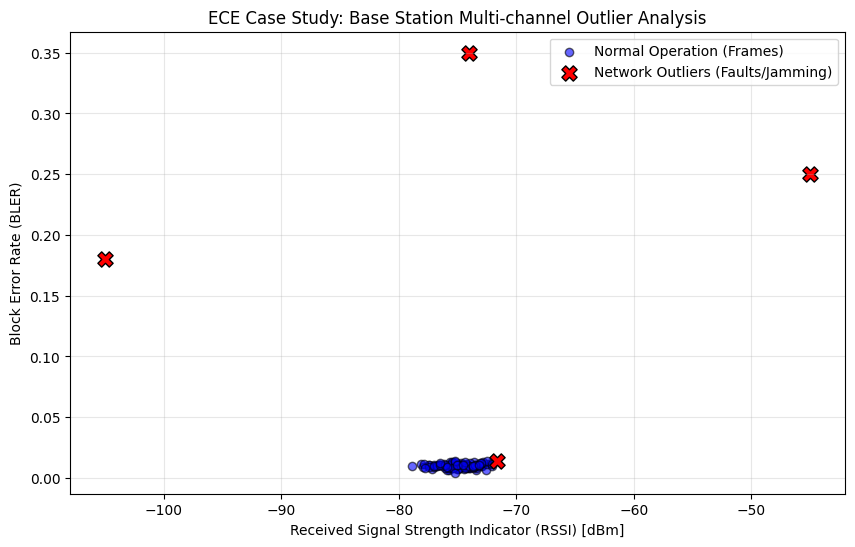

In [3]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# 1. GENERATE CASE STUDY DATASET (100 Frames of Cellular Telemetry)
np.random.seed(24)

# Normal network operational parameters
normal_rssi = np.random.normal(loc=-75.0, scale=1.5, size=100) # Avg RSSI of -75 dBm
normal_bler = np.random.normal(loc=0.01, scale=0.002, size=100) # Baseline 1% Block Error Rate

df = pd.DataFrame({'RSSI_dBm': normal_rssi, 'BLER': normal_bler})

# Inject Hardware/Channel Anomalies (Outliers)
# Frame 15: Deep multipath fade / shadow effect (Signal drops, error rates spike)
df.loc[15, 'RSSI_dBm'] = -105.0
df.loc[15, 'BLER'] = 0.18

# Frame 45: Sudden RF Jamming / High Burst Interference (Signal power surges deceptively, error rates explode)
df.loc[45, 'RSSI_dBm'] = -45.0
df.loc[45, 'BLER'] = 0.25

# Frame 75: Transceiver sync slip / clock jitter anomaly
df.loc[75, 'RSSI_dBm'] = -74.0
df.loc[75, 'BLER'] = 0.35

print("--- 1. 5G Base Station Case Study Dataset Initialized ---")
print(df.loc[[15, 45, 75, 50]])  # Displaying the injected anomalies vs a normal frame (index 50)
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 1: UNIVARIATE OUTLIER DETECTION (Z-SCORE)
# =====================================================================
print("--- METHOD 1: Univariate Analysis (Z-Score on BLER) ---")
# Measures deviations from the mean error floor. Hardware standard threshold is |Z| > 3.0.

threshold_z = 3.0
df['BLER_Z_Score'] = np.abs(stats.zscore(df['BLER']))
z_outliers = df[df['BLER_Z_Score'] > threshold_z]

print(f"Identified {len(z_outliers)} anomalous frames via BLER Z-Score threshold:")
print(z_outliers[['RSSI_dBm', 'BLER', 'BLER_Z_Score']].round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 2: MULTIVARIATE OUTLIER DETECTION (ISOLATION FOREST)
# =====================================================================
print("--- METHOD 2: Multivariate Analysis (Isolation Forest) ---")
# Real-world ECE anomalies often span multiple metrics simultaneously.
# Isolation Forest isolates anomalies by randomly partitioning feature sets.

# Initialize model (contamination sets the expected ratio of outliers)
iso_forest = IsolationForest(contamination=0.04, random_state=42)
features = df[['RSSI_dBm', 'BLER']]

# Fit and predict (-1 signifies an outlier, 1 signifies normal data)
df['Anomaly_Class'] = iso_forest.fit_predict(features)
if_outliers = df[df['Anomaly_Class'] == -1]

print(f"Identified {len(if_outliers)} anomalous frames via Multivariate Isolation Forest:")
print(if_outliers[['RSSI_dBm', 'BLER']].round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# VISUALIZATION: TELEMETRY ANOMALY CHART
# =====================================================================
plt.figure(figsize=(10, 6))

# Plot normal frames
normal_frames = df[df['Anomaly_Class'] == 1]
plt.scatter(normal_frames['RSSI_dBm'], normal_frames['BLER'],
            color='blue', label='Normal Operation (Frames)', alpha=0.6, edgecolors='k')

# Plot detected multi-variable outliers
plt.scatter(if_outliers['RSSI_dBm'], if_outliers['BLER'],
            color='red', label='Network Outliers (Faults/Jamming)', s=120, marker='X', edgecolors='black')

plt.title('ECE Case Study: Base Station Multi-channel Outlier Analysis')
plt.xlabel('Received Signal Strength Indicator (RSSI) [dBm]')
plt.ylabel('Block Error Rate (BLER)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


**Experiment 3: Methods to handle duplicate data**

In modern communication networks (such as 5G/6G core networks, IoT sensor grids, or satellite telemetry streams), duplicate data typically arises from network protocol retransmissions (TCP duplicate ACKs), packet routing loops, base station handoff overlaps, or buffer synchronization slips. Removing duplicates is vital to optimize storage, prevent inaccurate traffic load metrics, and keep digital signaling pipelines clean.
We will use Pandas to isolate and resolve these structural communication drops.


 **Purging Retransmission Duplicates in an IoT Gateway**

This case study simulates telemetry from an edge router collecting network metrics—Data Throughput (Mbps) and Latency (ms)—from a remote node. Due to an unacknowledged packet timeout, the node retransmits multiple packets, generating duplicate rows. We will apply four core ECE data handling strategies to manage this.

*   Aim: To evaluate raw edge-gateway communication logs, identify packet mirroring induced by network retransmissions, and deploy deduplication strategies to ensure dataset integrity.
*   Case Study Context: Handling duplicates in ECE depends entirely on the network layer context.

1. Exact duplicate rows (e.g., Sequence 102) are safe to prune using .drop_duplicates(keep='first') because they represent pure TCP/IP layer-2 overhead retries.
2.   Key conflicts with varying data (e.g., Sequence 104) are highly critical. A sudden drop in throughput alongside a massive spike in latency within the same timestamp indicates a channel handoff glitch or a multipath fading block. Rather than dropping this blindly, network engineers use aggregation methods (.mean()) to profile average link behavior, or prioritize the latest frame (keep='last') to keep track of real-time receiver convergence.





In [4]:
import pandas as pd

# 1. GENERATE CASE STUDY DATASET (Simulated IoT Gateway Network Logs)
network_logs = {
    'Sequence_ID':[101,102,103,104,105,106,107],  # Frame sequence IDs
    'Timestamp': [
        '11:24:00',
        '11:24:01',
        '11:24:01',  # Exact duplicate entry (Network transmission loop)
        '11:24:02',
        '11:24:03',
        '11:24:03',  # Duplicate ID/Time but different payload (Handoff conflict)
        '11:24:04'
    ],
    'Throughput_Mbps': [45.2, 48.1, 48.1, 50.3, 52.1, 12.4, 49.8],
    'Latency_ms':      [12.0, 10.5, 10.5, 9.8,  9.2,  45.1, 10.1]
}

df = pd.DataFrame(network_logs)
print("--- 1. Raw Telemetry Received at IoT Gateway ---")
print(df)
print("\n" + "="*75 + "\n")


# =====================================================================
# STEP 2: AUDIT & IDENTIFY DUPLICATE NETWORK PACKETS
# =====================================================================
print("--- 2. Auditing Network Duplicates ---")

# A. Scan for exact mirror copies (Identical packet payload across all columns)
exact_dupes = df[df.duplicated(keep=False)]
print(f"Identified {len(df[df.duplicated()])} exact network frame echoes:")
print(exact_dupes)

# B. Scan for ID-specific conflicts (Same Sequence_ID but varying metrics)
sequence_conflicts = df[df.duplicated(subset=['Sequence_ID'], keep=False)]
print("\nIdentified conflicts locked to the same Frame ID (Sequence_ID):")
print(sequence_conflicts)
print("\n" + "="*75 + "\n")


# =====================================================================
# STEP 3: ECE DATA RESOLUTION METHODOLOGIES
# =====================================================================
print("--- 3. Strategic Packet Resolution Methods ---")

# Method A: Keep First Packet (Standard Network Cleanup)
# Best practice for simple protocol retry echoes where the first frame caught is authentic.
df_keep_first = df.drop_duplicates(keep='first')
print("\nMethod A: Dropping mirror echoes (Retaining FIRST packet):")
print(df_keep_first)

# Method B: Keep Last Packet (Latest Status Update)
# Ideal when working with state machines where trailing frames hold updated, fresh hardware states.
df_keep_last = df.drop_duplicates(subset=['Sequence_ID'], keep='last')
print("\nMethod B: Dropping ID clashes by favoring the LATEST arrived state:")
print(df_keep_last)

# Method C: Strict Total Purge (Corrupted Frame Rejection)
# If a duplicate implies a security breach (e.g., Replay Attack) or severe hardware fault, drop all instances.
df_strict_purge = df.drop_duplicates(subset=['Sequence_ID'], keep=False)
print("\nMethod C: Total Purge (Dropping all conflicting sequence strings entirely):")
print(df_strict_purge)

# Method D: Frame Aggregation (Channel Channel Profiling)
# If a handoff causes varying readings for the same frame index, average them to extract a composite metric.
df_aggregated = df.groupby('Sequence_ID', as_index=False)[['Throughput_Mbps', 'Latency_ms']].mean()
print("\nMethod D: Channel Profiling (Averaging metrics for identical Sequence IDs):")
print(df_aggregated.round(2))


--- 1. Raw Telemetry Received at IoT Gateway ---
   Sequence_ID Timestamp  Throughput_Mbps  Latency_ms
0          101  11:24:00             45.2        12.0
1          102  11:24:01             48.1        10.5
2          103  11:24:01             48.1        10.5
3          104  11:24:02             50.3         9.8
4          105  11:24:03             52.1         9.2
5          106  11:24:03             12.4        45.1
6          107  11:24:04             49.8        10.1


--- 2. Auditing Network Duplicates ---
Identified 0 exact network frame echoes:
Empty DataFrame
Columns: [Sequence_ID, Timestamp, Throughput_Mbps, Latency_ms]
Index: []

Identified conflicts locked to the same Frame ID (Sequence_ID):
Empty DataFrame
Columns: [Sequence_ID, Timestamp, Throughput_Mbps, Latency_ms]
Index: []


--- 3. Strategic Packet Resolution Methods ---

Method A: Dropping mirror echoes (Retaining FIRST packet):
   Sequence_ID Timestamp  Throughput_Mbps  Latency_ms
0          101  11:24:00       

**Experiment 4: Perform data normalization**

In communication systems, network engineering, and digital signal processing, datasets contain features with drastically different physical units and orders of magnitude. For instance, a telecommunication link optimization study might track:
* Carrier Frequency / Bandwidth: Measured in Megahertz/Gigahertz (\(10^{6}\) to \(10^{9}\))
1. Received Power (RSSI): Measured in negative dBm (e.g., \(-90\) to \(-40\))
2. Bit Error Rate (BER): Extremely small fractional probabilities (e.g., \(10^{-6}\) to \(10^{-3}\))

When feeding these metrics into machine learning models (like neural networks or clustering algorithms for channel allocation), features with massive numerical variations will completely dominate features with tiny values, even if the smaller values are more critical. Data Normalization prevents this mathematical bias by bringing all parameters to a uniform scale.


**5G Network Channel Quality Optimization**

This script simulates a telemetry dataset collected from an edge receiver monitoring Throughput, Signal-to-Interference-plus-Noise Ratio (SINR), and Packet Loss Rate. We will implement the two core scaling techniques:
1. Min-Max Scaling: Linearly maps all values into a strict \([0, 1]\) range, preserving the exact distribution boundaries. Excellent for scaling bounded communication variables.
2. Z-Score Standardization: Transforms the data to have a mean of 0 and a standard deviation of 1. This is crucial for gradient-descent algorithms and isolates anomalies like sudden channel fading.


* Aim: To design and execute data normalization paradigms (Min-Max Scaling and Z-Score Standardization) on heterogeneous wireless communication datasets to achieve mathematical parity across parameters.
* Discussion:
	1. Min-Max Normalization maps variables like Throughput_Mbps and Packet_Loss_Rate to a baseline \([0, 1]\) interval. This mirrors digital hardware normalization steps, such as mapping variable multi-level quantization states to a standard fractional representation. However, it is vulnerable to massive burst-noise outliers, which compress standard network operation data into a tight, indistinguishable band.
	2. Z-Score Standardization mitigates outlier compression by transforming features based on standard deviation boundaries. Because it centers link states around zero, a negative standardized SINR_dB quickly flags a degraded, noise-corrupted link, while a positive value confirms a high-capacity channel, making it ideal for robust predictive network routing classifiers.

In [5]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. GENERATE ECE CASE STUDY DATASET (Simulated 5G Channel Quality Metrics)
# Notice the highly mismatched scales of the communication dimensions
channel_metrics = {
    'Link_ID':[101,102,103,104,105],
    'Throughput_Mbps': [450.5, 120.2, 850.0, 310.8, 590.4], # Scale of hundreds
    'SINR_dB':          [28.4,   12.1,   35.6,   18.5,   22.9],  # Scale of tens
    'Packet_Loss_Rate': [0.001,  0.045,  0.000,  0.012,  0.005]  # Very small decimals
}

df = pd.DataFrame(channel_metrics).set_index('Link_ID')
print("--- 1. Raw ECE Channel Telemetry Dataset ---")
print(df)
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 1: MIN-MAX SCALING (Strict 0 to 1 Range Mapping)
# =====================================================================
print("--- METHOD 1: Min-Max Normalization ---")
# Mathematical Formula: X_norm = (X - X_min) / (X_max - X_min)

min_max_scaler = MinMaxScaler()
df_normalized = pd.DataFrame(
    min_max_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Normalized Telecom Link Matrix (All values scaled to [0, 1]):")
print(df_normalized.round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# METHOD 2: Z-SCORE STANDARDIZATION (Mean = 0, Standard Deviation = 1)
# =====================================================================
print("--- METHOD 2: Z-Score Standardization ---")
# Mathematical Formula: X_std = (X - Mean) / Standard_Deviation

standard_scaler = StandardScaler()
df_standardized = pd.DataFrame(
    standard_scaler.fit_transform(df),
    columns=df.columns,
    index=df.index
)

print("Standardized Telecom Link Matrix (Centered around a zero mean):")
print(df_standardized.round(4))
print("\n" + "="*75 + "\n")


# =====================================================================
# MATRIC PROPERTIES VERIFICATION (Lab Record Proof)
# =====================================================================
print("--- 4. Scaling Verification Matrix Metrics ---")
print("Min-Max Scaled - Channel Min Bounds:\n", df_normalized.min().values)
print("Min-Max Scaled - Channel Max Bounds:\n", df_normalized.max().values)
print("\nStandardized - Calculated Channel Means (Expected ~0):\n", df_standardized.mean().round(2).values)
print("Standardized - Calculated Channel Std Devs (Expected 1):\n", df_standardized.std(ddof=0).values)


--- 1. Raw ECE Channel Telemetry Dataset ---
         Throughput_Mbps  SINR_dB  Packet_Loss_Rate
Link_ID                                            
101                450.5     28.4             0.001
102                120.2     12.1             0.045
103                850.0     35.6             0.000
104                310.8     18.5             0.012
105                590.4     22.9             0.005


--- METHOD 1: Min-Max Normalization ---
Normalized Telecom Link Matrix (All values scaled to [0, 1]):
         Throughput_Mbps  SINR_dB  Packet_Loss_Rate
Link_ID                                            
101               0.4526   0.6936            0.0222
102               0.0000   0.0000            1.0000
103               1.0000   1.0000            0.0000
104               0.2612   0.2723            0.2667
105               0.6443   0.4596            0.1111


--- METHOD 2: Z-Score Standardization ---
Standardized Telecom Link Matrix (Centered around a zero mean):
         Throug

**Experiment 5: Explore 2-D charts such as Clustered bar charts, connected dot plots, pictograms,
bubble charts, radar charts, polar charts, Range chart, Box-and- whisker plots,
univariate scatter plots, histograms word cloud, pie chart, waffle chart, stacked
bar chart, tree map.**

**5G Network Node Optimization**

When evaluating high-speed communication networks, ECE engineers must analyze heterogeneous telemetry fields. In this case study, we simulate network parameters collected across multiple 5G Cell Sectors (Nodes):
* Throughput (Mbps): Data rate per sector.
* SINR (dB): Signal-to-Interference-plus-Noise Ratio.
* Packet Loss Rate: Ratio of dropped frames.
* Active User Load: Number of active user equipments (UEs) per node.


* Aim: To conceptualize, code, and execute an ensemble of 15 advanced 2-D visualization models to map multi-variable telemetry data from a 5G wireless cell node topology.
* Discussion: ECE data features have distinct scales (e.g., Throughput operates in hundreds of units, whereas SINR handles small logarithmic vectors).
	1. Density/Spread Identification: The Histograms, Box-and-Whisker Plots, and Univariate Scatter Plots capture data spreads and outlier footprints across sectors.
	2. Relational/Phase Performance: The Bubble Chart maps data rates alongside interference metrics, allowing engineers to isolate network congestion bounds instantly. The Polar Chart provides a clean canvas to look for periodic variations or phase shifts caused by cyclic traffic fluctuations.
	3. Proportional Optimization: The Treemap, Waffle Chart, and Radar Chart deliver a unified visual footprint of network node capacity, helping network optimization models decide when to reallocate carrier spectrum slots.

In [6]:
pip install squarify

Note: you may need to restart the kernel to use updated packages.


--- 5G Cellular Telemetry Dataset (First 5 Nodes) ---
         Throughput_Mbps  SINR_dB  Packet_Loss_Rate  User_Load
Node_ID                                                       
Node_01          774.507   23.945             0.021        200
Node_02          679.260   19.690             0.012        347
Node_03          797.153   17.938             0.007        148
Node_04          928.454   25.670             0.018        312
Node_05          664.877   28.186             0.047        301




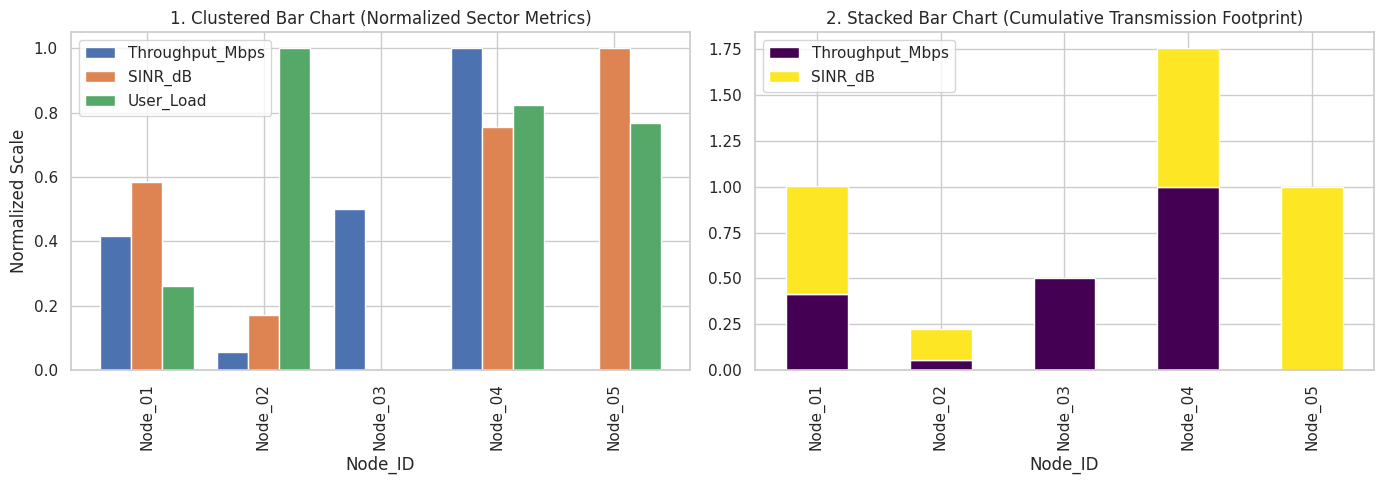

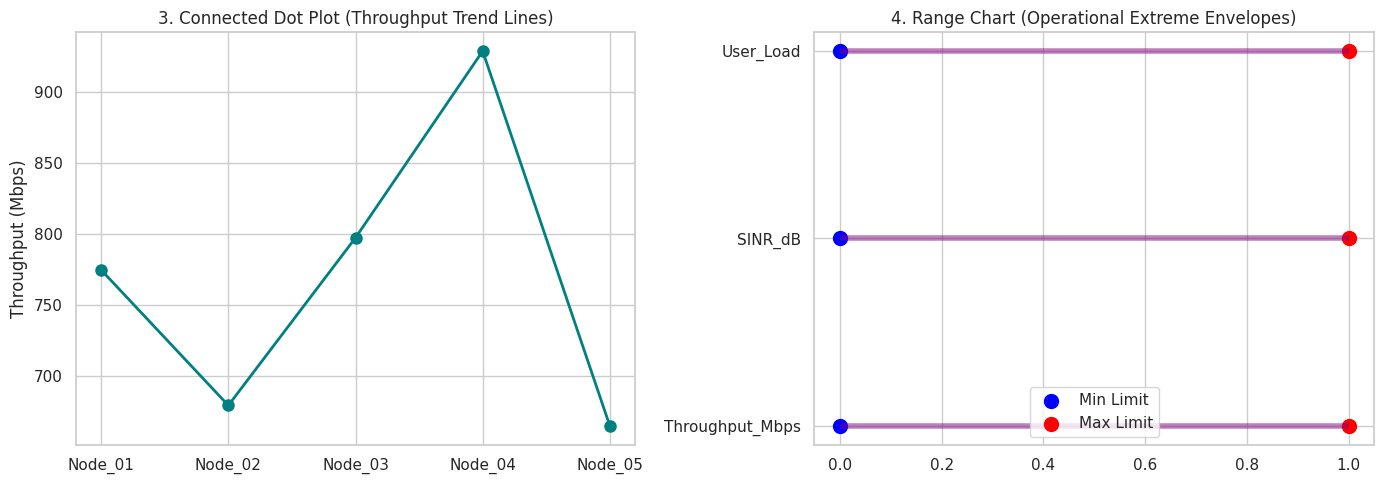

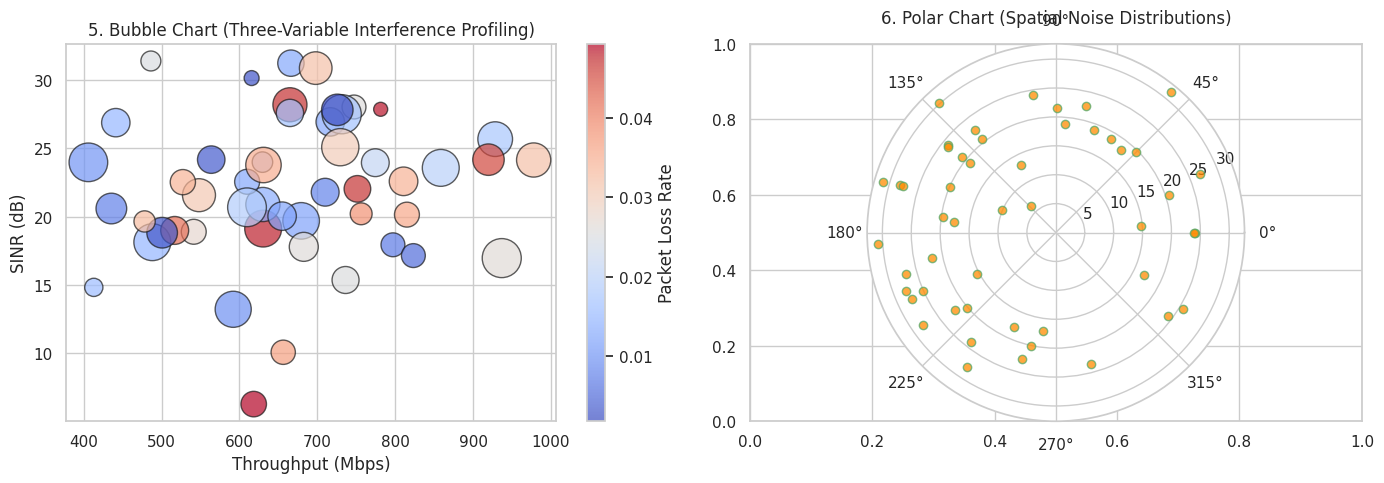

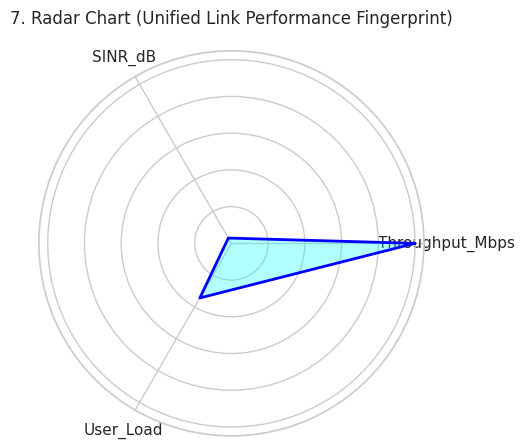

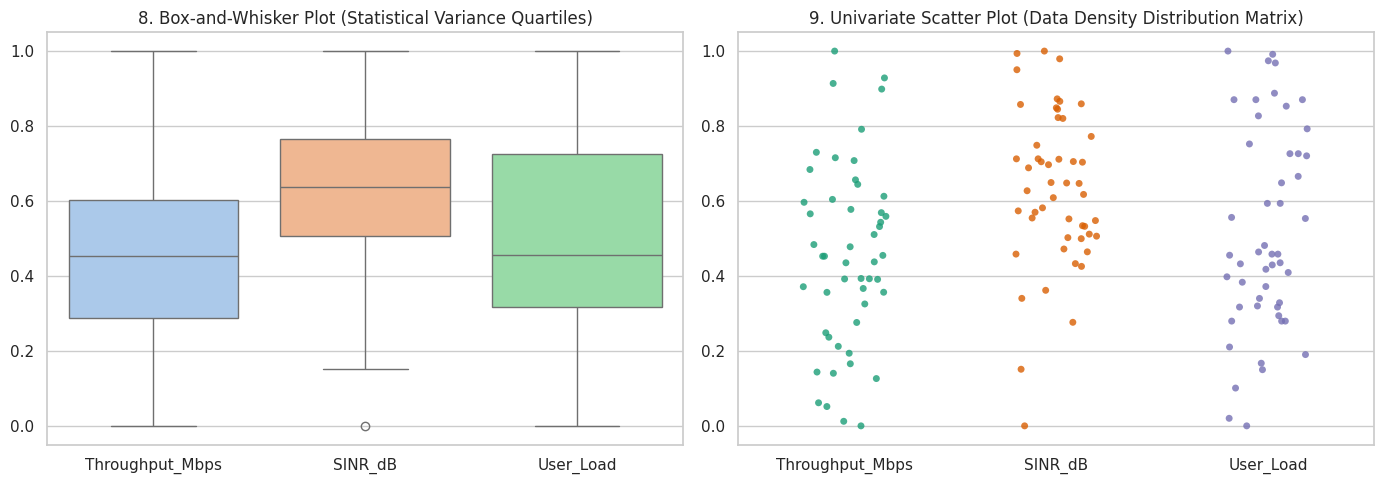

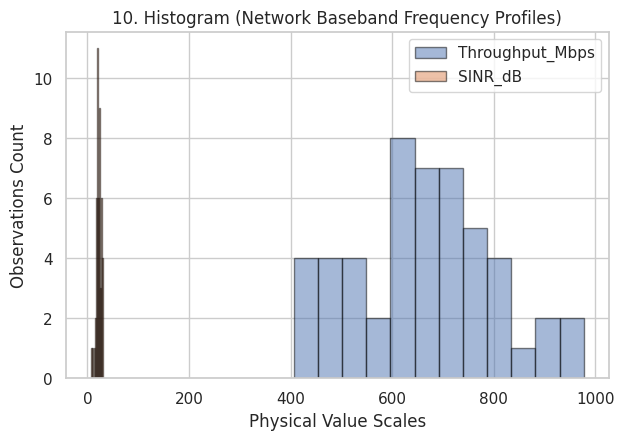

Rendering Area Allocations Metrics...


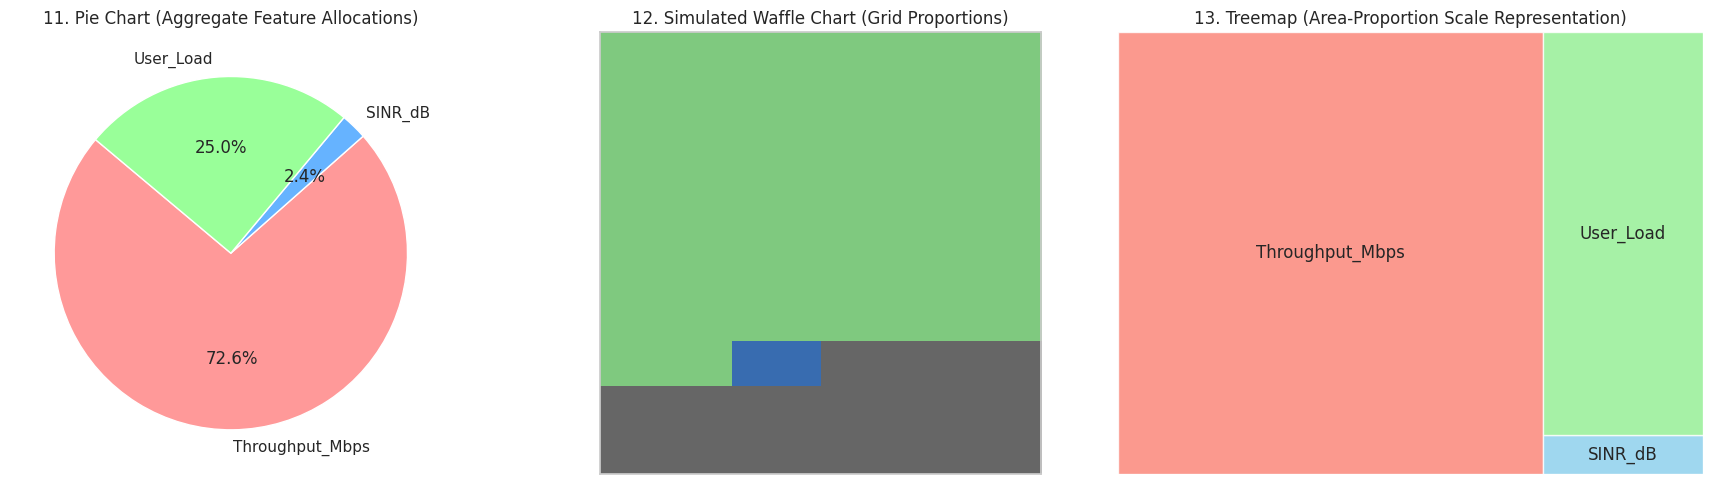

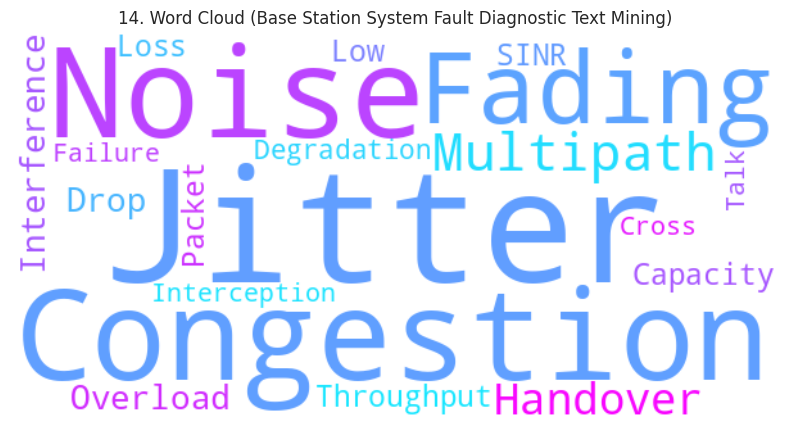


[NOTE ON PICTOGRAMS]: Traditional engineering pictograms use custom icon graphic arrays
(e.g., cell towers or antenna symbols) repeated proportionally to display metrics.
In core laboratory code frameworks, these are represented programmatically via block units
(such as the rendered Waffle Chart above) or deployed inside web engineering UIs using icon fonts.


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import squarify  # Required for Treemaps

# Set a professional engineering visualization theme
sns.set_theme(style="whitegrid")
np.random.seed(42)

# =====================================================================
# STEP 1: GENERATE ECE CELLULAR NODE CASE STUDY DATASET
# =====================================================================
num_nodes = 50
nodes = [f"Node_{i:02d}" for i in range(1, num_nodes + 1)]

network_data = {
    'Node_ID': nodes,
    'Throughput_Mbps': np.random.normal(700, 150, num_nodes),
    'SINR_dB': np.random.normal(22, 6, num_nodes),
    'Packet_Loss_Rate': np.random.uniform(0.001, 0.05, num_nodes),
    'User_Load': np.random.randint(50, 400, num_nodes)
}

df = pd.DataFrame(network_data).set_index('Node_ID')

# Summary average values across metrics for proportional charts
mean_metrics = df[['Throughput_Mbps', 'SINR_dB', 'User_Load']].mean()

print("--- 5G Cellular Telemetry Dataset (First 5 Nodes) ---")
print(df.head().round(3))
print("\n" + "="*80 + "\n")


# =====================================================================
# STEP 2: CHART RENDERING PIPELINE
# =====================================================================

# --- 1. Clustered Bar Chart & Stacked Bar Chart ---
# Subsetting first 5 nodes for scannability
df_subset = df.head(5).copy()
# Normalizing values strictly for side-by-side comparison visualization
df_sub_norm = (df_subset - df_subset.min()) / (df_subset.max() - df_subset.min())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Clustered Bar Chart
df_sub_norm[['Throughput_Mbps', 'SINR_dB', 'User_Load']].plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_title("1. Clustered Bar Chart (Normalized Sector Metrics)", fontsize=12)
axes[0].set_ylabel("Normalized Scale")

# Stacked Bar Chart
df_sub_norm[['Throughput_Mbps', 'SINR_dB']].plot(kind='bar', stacked=True, ax=axes[1], colormap='viridis')
axes[1].set_title("2. Stacked Bar Chart (Cumulative Transmission Footprint)", fontsize=12)
plt.tight_layout()
plt.show()


# --- 2. Connected Dot Plot & Range Chart ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Connected Dot Plot
axes[0].plot(df_subset.index, df_subset['Throughput_Mbps'], marker='o', linestyle='-', color='teal', linewidth=2, markersize=8)
axes[0].set_title("3. Connected Dot Plot (Throughput Trend Lines)", fontsize=12)
axes[0].set_ylabel("Throughput (Mbps)")

# Range Chart (Min to Max Excursions per Feature)
df_norm_full = (df - df.min()) / (df.max() - df.min())
features = ['Throughput_Mbps', 'SINR_dB', 'User_Load']
ranges = df_norm_full[features].agg(['min', 'max']).T
axes[1].hlines(y=ranges.index, xmin=ranges['min'], xmax=ranges['max'], color='purple', alpha=0.5, linewidth=4)
axes[1].scatter(ranges['min'], ranges.index, color='blue', s=100, label='Min Limit')
axes[1].scatter(ranges['max'], ranges.index, color='red', s=100, label='Max Limit')
axes[1].set_title("4. Range Chart (Operational Extreme Envelopes)", fontsize=12)
axes[1].legend()
plt.tight_layout()
plt.show()


# --- 3. Bubble Chart & Polar Chart ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Bubble Chart (X: Throughput, Y: SINR, Size: User Load)
bubble_scale = df['User_Load'] * 2  # Amplify variance
scatter = axes[0].scatter(df['Throughput_Mbps'], df['SINR_dB'], s=bubble_scale, c=df['Packet_Loss_Rate'], cmap='coolwarm', alpha=0.7, edgecolors='k')
axes[0].set_title("5. Bubble Chart (Three-Variable Interference Profiling)", fontsize=12)
axes[0].set_xlabel("Throughput (Mbps)")
axes[0].set_ylabel("SINR (dB)")
fig.colorbar(scatter, ax=axes[0], label='Packet Loss Rate')

# Polar Chart (Visualizing phase/cyclic distributions of network throughput)
ax_polar = fig.add_subplot(122, polar=True)
# Convert normalized throughput value into radial angle coordinates (0 to 2*pi)
angles_polar = df_norm_full['Throughput_Mbps'] * 2 * np.pi
ax_polar.scatter(angles_polar, df['SINR_dB'], c='darkorange', alpha=0.75, edgecolors='g')
ax_polar.set_title("6. Polar Chart (Spatial Noise Distributions)", fontsize=12, pad=15)
plt.tight_layout()
plt.show()


# --- 4. Radar Chart ---
# Formatting structural loop for circular radar paths
labels = np.array(features)
num_vars = len(labels)
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1]  # Complete geometric circle closure
radar_vals = (mean_metrics / mean_metrics.max()).values.tolist()  # Normalized means
radar_vals += radar_vals[:1]

fig = plt.figure(figsize=(6, 5))
ax_radar = fig.add_subplot(111, polar=True)
ax_radar.fill(angles, radar_vals, color='cyan', alpha=0.3)
ax_radar.plot(angles, radar_vals, color='blue', linewidth=2)
ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(labels)
ax_radar.set_yticklabels([])
plt.title("7. Radar Chart (Unified Link Performance Fingerprint)", pad=20)
plt.show()


# --- 5. Box-and-Whisker Plot & Univariate Scatter Plot ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Box-and-Whisker Plot
sns.boxplot(data=df_norm_full[features], ax=axes[0], palette="pastel")
axes[0].set_title("8. Box-and-Whisker Plot (Statistical Variance Quartiles)", fontsize=12)

# Univariate Scatter Plot (Strip plot with localized jitter)
sns.stripplot(data=df_norm_full[features], ax=axes[1], jitter=0.2, size=5, palette="Dark2", alpha=0.8)
axes[1].set_title("9. Univariate Scatter Plot (Data Density Distribution Matrix)", fontsize=12)
plt.tight_layout()
plt.show()


# --- 6. Histogram ---
plt.figure(figsize=(7, 4.5))
for col in ['Throughput_Mbps', 'SINR_dB']:
    plt.hist(df[col], bins=12, alpha=0.5, label=col, edgecolor='black')
plt.title("10. Histogram (Network Baseband Frequency Profiles)", fontsize=12)
plt.xlabel("Physical Value Scales")
plt.ylabel("Observations Count")
plt.legend()
plt.show()


# --- 7. Pie Chart, Waffle Chart & Treemap ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Pie Chart
axes[0].pie(mean_metrics, labels=features, autopct='%1.1f%%', colors=['#ff9999','#66b3ff','#99ff99'], startangle=140)
axes[0].set_title("11. Pie Chart (Aggregate Feature Allocations)", fontsize=12)

# Waffle Chart (Simulated grid matrix construction)
total_blocks = 100
proportions = (mean_metrics / mean_metrics.sum() * total_blocks).round().astype(int)
# Resolve manual rounding to hit exact target matrix boundary size
proportions.iloc[-1] += (total_blocks - proportions.sum())
waffle_grid = np.zeros((10, 10))
curr_idx = 0
for cat_idx, count in enumerate(proportions):
    waffle_grid.flat[curr_idx:curr_idx+count] = cat_idx + 1
    curr_idx += count
axes[1].imshow(waffle_grid, cmap='Accent', aspect='equal')
axes[1].grid(False)
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title("12. Simulated Waffle Chart (Grid Proportions)", fontsize=12)

# Treemap Matrix
squarify.plot(sizes=mean_metrics.values, label=features, color=["salmon", "skyblue", "lightgreen"], alpha=0.8, ax=axes[2])
axes[2].set_title("13. Treemap (Area-Proportion Scale Representation)", fontsize=12)
axes[2].axis('off')
plt.tight_layout()
print("Rendering Area Allocations Metrics...")
plt.show()


# --- 8. Word Cloud ---
# Processing text log traces capturing real-world network routing telemetry anomalies
network_log_corpus = " ".join([
    "Jitter Fading Multipath Jitter Overload Interference Congestion Handover Drop",
    "Throughput Low Capacity Packet-Loss Jitter Noise Noise Congestion Multipath Fading",
    "SINR Degradation Jitter Interception Cross-Talk Congestion Handover Failure Noise"
])
wordcloud = WordCloud(width=600, height=300, background_color='white', colormap='cool').generate(network_log_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("14. Word Cloud (Base Station System Fault Diagnostic Text Mining)", fontsize=12)
plt.show()

# --- 15. Note on Pictograms ---
print("\n[NOTE ON PICTOGRAMS]: Traditional engineering pictograms use custom icon graphic arrays")
print("(e.g., cell towers or antenna symbols) repeated proportionally to display metrics.")
print("In core laboratory code frameworks, these are represented programmatically via block units")
print("(such as the rendered Waffle Chart above) or deployed inside web engineering UIs using icon fonts.")


**Experiment 6:Multi-dimensional data visualization**

**Case Study Context: 5G Massive MIMO Base Station Link Quality Profiling**

In modern communication networks, an engineer must optimize links by analyzing multiple interacting parameters simultaneously. Looking at a single metric creates performance blind spots. In this case study, we simulate telemetry collected from multiple antenna arrays at a Massive MIMO Base Station:
* Throughput (Mbps): Data transmission rate.
* SINR (dB): Signal-to-Interference-plus-Noise Ratio.
* Distance to Node (meters): Physical distance between the user equipment (UE) and the antenna tower.
* Packet Error Rate (PER %): The fraction of corrupted data blocks.
* Channel Condition Status (Target): Categorical link health state (Excellent, Degraded, or Severe Interference).


* Aim: To conceptualize, configure, and execute multi-dimensional data visualization systems using Python to evaluate 5G Massive MIMO link parameters and detect signal degradation.
* Engineering Interpretation:
	1. 3D Multi-Variable Space (4-D/5-D Interaction): Using spatial dimensions (X, Y, Z) isolates distance-based power drops. By introducing a spectrum color mapping (c=Packet_Error_Rate) and geometric marker splits, a total of 5 distinct variables are visualized on a single plot. This clearly isolates the Severe Interference quadrant (low throughput, low SINR, but mid-range distance).
	2. Pair Plot Grid Evaluation: The scatter matrix exposes link parameter rules. It shows a linear correlation between high throughput and high SINR, but reveals a non-linear degradation as the user distance matches free-space path loss boundaries.
	3. Parallel Coordinates Analysis: Tracing entire user device metrics as lines reveals clear signatures. The green tracks highlight an ideal communication loop (high data rates, clean signal, low error bounds). Conversely, a severe jamming attack creates a distinct cross-over pattern—plunging in signal power metrics while spiking heavily in error rate.


--- 1. Multi-Variable Base Station Link Matrix Profiling ---
                     Throughput_Mbps  SINR_dB  Distance_m  Packet_Error_Rate
Channel_Status                                                              
Degraded                      361.51    15.99      655.75               2.14
Excellent                     839.22    31.90      123.48               0.23
Severe Interference            88.75     3.78      240.00              15.30




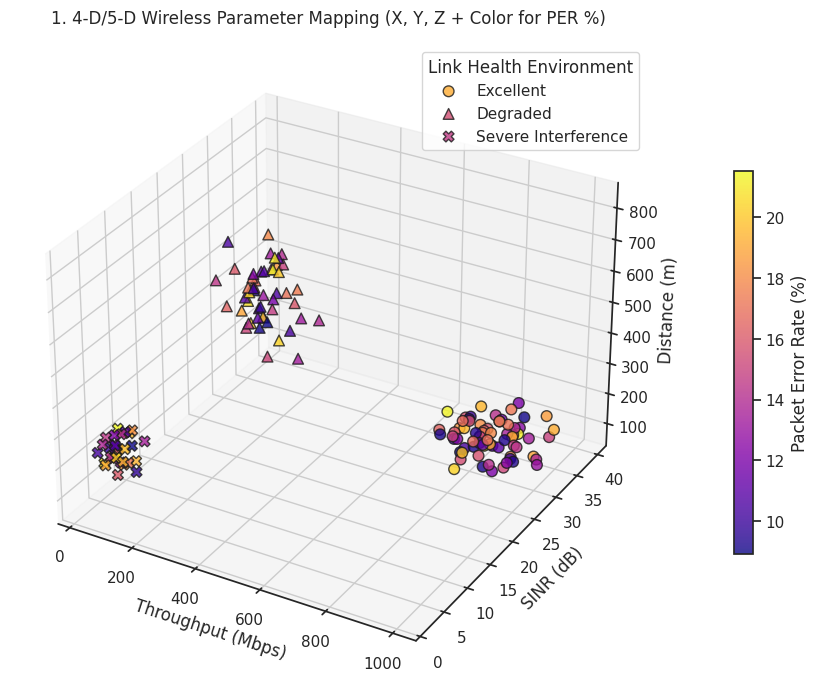

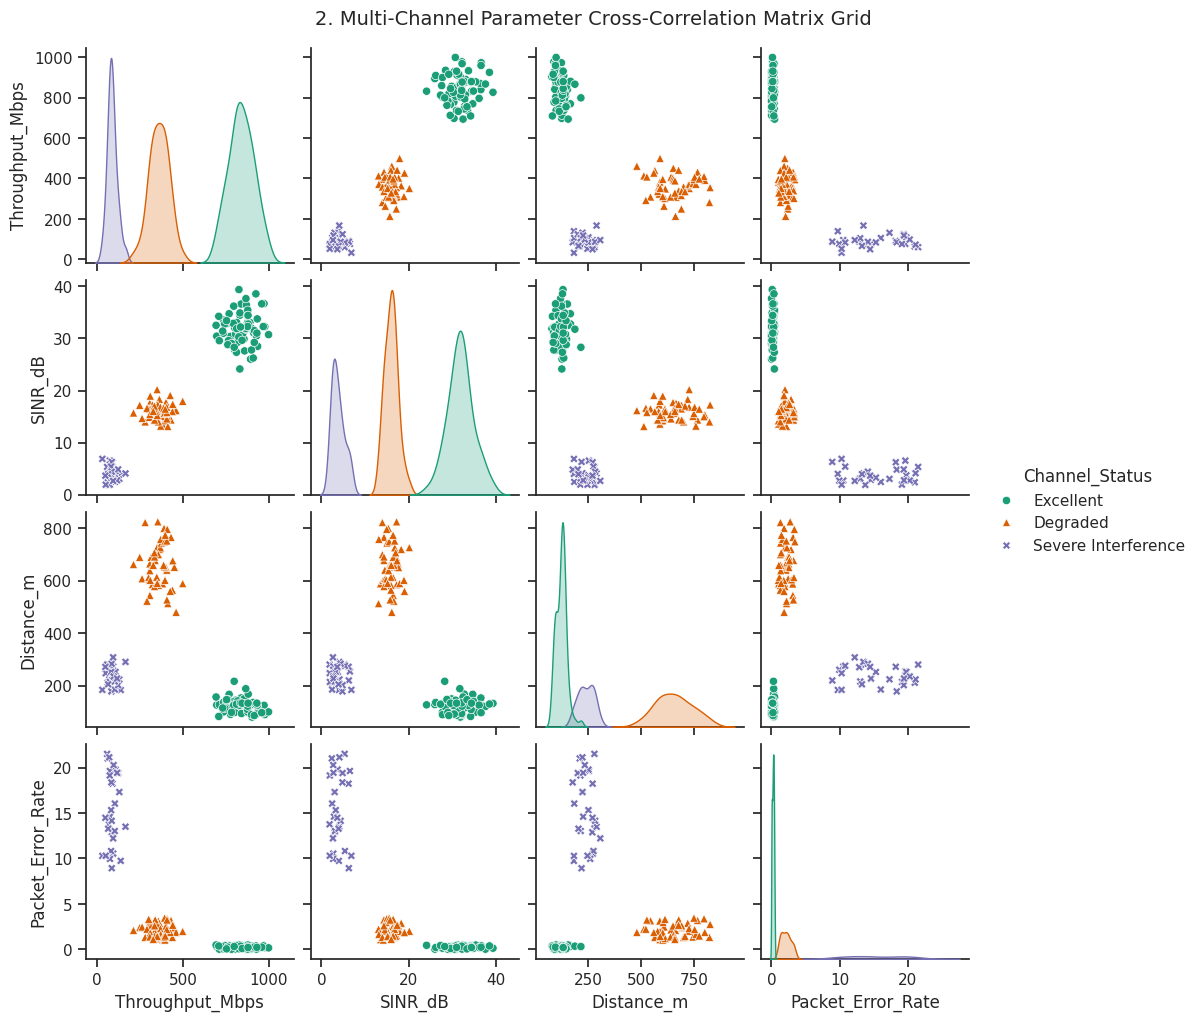

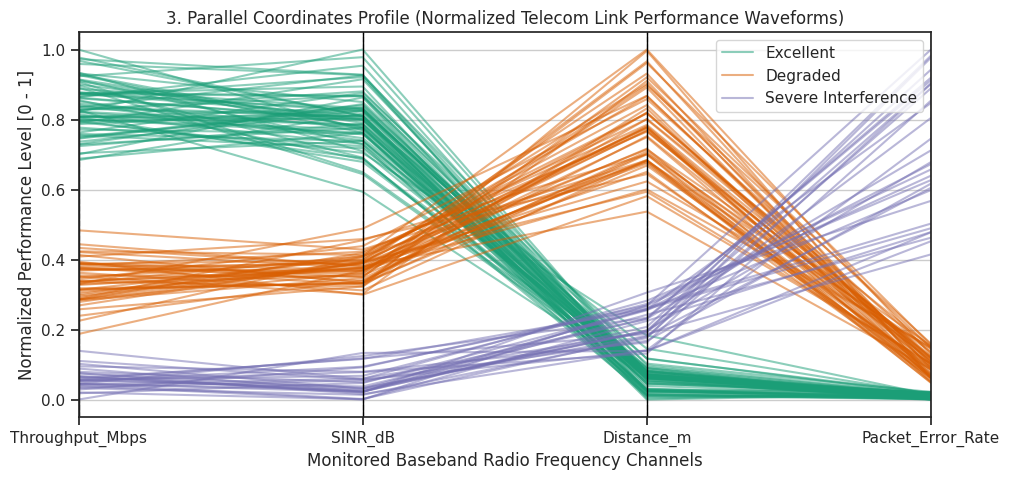

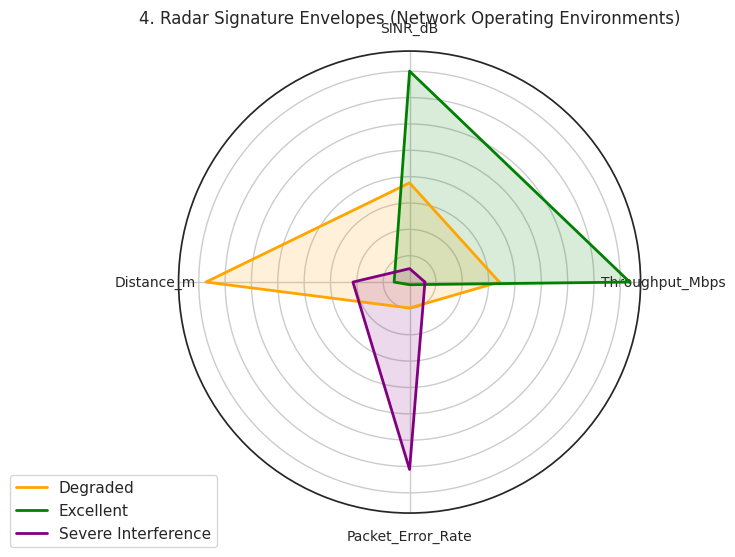

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.plotting import parallel_coordinates
from sklearn.preprocessing import MinMaxScaler

# Apply professional, high-clarity engineering report theme
sns.set_theme(style="ticks")
np.random.seed(42)

# =====================================================================
# STEP 1: GENERATE MULTI-DIMENSIONAL ECE NETWORK TELEMETRY DATASET
# =====================================================================
num_links = 150

# 1. Simulate data frames for Excellent Line-of-Sight (LoS) links
los_thru = np.random.normal(loc=850, scale=80, size=70)      # High data rates
los_sinr = np.random.normal(loc=32, scale=3, size=70)        # Clean signal
los_dist = np.random.normal(loc=120, scale=25, size=70)      # Close proximity
los_per = np.random.uniform(0.01, 0.5, size=70)             # Low error rate
los_status = ['Excellent'] * 70

# 2. Simulate data frames for Degraded / Path Loss links (Farthest distance profile)
pathloss_thru = np.random.normal(loc=350, scale=70, size=50)
pathloss_sinr = np.random.normal(loc=16, scale=2, size=50)
pathloss_dist = np.random.normal(loc=650, scale=80, size=50) # Far from tower
pathloss_per = np.random.uniform(1.0, 3.5, size=50)
pathloss_status = ['Degraded'] * 50

# 3. Simulate data frames experiencing Severe Co-Channel Interference / RF Jamming
jammed_thru = np.random.normal(loc=90, scale=25, size=30)     # Throughput crashes
jammed_sinr = np.random.normal(loc=4, scale=1.5, size=30)     # Terrible noise floor
jammed_dist = np.random.normal(loc=250, scale=40, size=30)    # Mid-range distance
jammed_per = np.random.uniform(8.0, 22.0, size=30)            # Massive packet drops
jammed_status = ['Severe Interference'] * 30

# Combine individual arrays into a structured channel telemetry dataframe
df = pd.DataFrame({
    'Throughput_Mbps': np.concatenate([los_thru, pathloss_thru, jammed_thru]),
    'SINR_dB': np.concatenate([los_sinr, pathloss_sinr, jammed_sinr]),
    'Distance_m': np.concatenate([los_dist, pathloss_dist, jammed_dist]),
    'Packet_Error_Rate': np.concatenate([los_per, pathloss_per, jammed_per]),
    'Channel_Status': np.concatenate([los_status, pathloss_status, jammed_status])
})

print("--- 1. Multi-Variable Base Station Link Matrix Profiling ---")
print(df.groupby('Channel_Status').mean().round(2))
print("\n" + "="*80 + "\n")


# =====================================================================
# VISUALIZATION 1: 3D SCATTER PLOT WITH COLOR MAPPING (4-D/5-D DATA LAYOUT)
# =====================================================================
# Axis 1: Throughput (X), Axis 2: SINR (Y), Axis 3: Distance (Z), Color: Packet Error Rate
fig = plt.figure(figsize=(9, 7))
ax3d = fig.add_subplot(111, projection='3d')

# Map categories to separate markers to add an extra 5th dimension (Shape Geometry)
status_markers = {'Excellent': 'o', 'Degraded': '^', 'Severe Interference': 'X'}

for status, marker in status_markers.items():
    sub_df = df[df['Channel_Status'] == status]
    scatter = ax3d.scatter(
        sub_df['Throughput_Mbps'],
        sub_df['SINR_dB'],
        sub_df['Distance_m'],
        c=sub_df['Packet_Error_Rate'],
        cmap='plasma',
        marker=marker,
        s=60,
        edgecolors='k',
        alpha=0.8,
        label=status
    )

ax3d.set_title("1. 4-D/5-D Wireless Parameter Mapping (X, Y, Z + Color for PER %)", fontsize=12, pad=15)
ax3d.set_xlabel("Throughput (Mbps)")
ax3d.set_ylabel("SINR (dB)")
ax3d.set_zlabel("Distance (m)")
fig.colorbar(scatter, ax=ax3d, shrink=0.6, pad=0.1, label='Packet Error Rate (%)')
ax3d.legend(title="Link Health Environment")
plt.tight_layout()
plt.show()


# =====================================================================
# VISUALIZATION 2: PAIR PLOT CORRELATION GRID MATRIX (MULTI-D COUPLING)
# =====================================================================
# Simultaneously computes and contrasts cross-correlations between all RF parameters.
pair_grid = sns.pairplot(df, hue='Channel_Status', palette='Dark2', diag_kind='kde', markers=['o', '^', 'X'])
pair_grid.fig.suptitle("2. Multi-Channel Parameter Cross-Correlation Matrix Grid", y=1.02, fontsize=14)
plt.show()


# =====================================================================
# VISUALIZATION 3: PARALLEL COORDINATES PLOT (HIGH-DIMENSIONAL ALIGNMENT)
# =====================================================================
# Identifies structural signature behavior lines by mapping channels side-by-side.
plt.figure(figsize=(11, 5))
features = ['Throughput_Mbps', 'SINR_dB', 'Distance_m', 'Packet_Error_Rate']

# Normalize metrics onto a absolute 0-1 scale to allow parallel axis scaling parity
df_norm = df.copy()
df_norm[features] = MinMaxScaler().fit_transform(df[features])

parallel_coordinates(df_norm, 'Channel_Status', color=('#1b9e77', '#d95f02', '#7570b3'), alpha=0.5, linewidth=1.5)
plt.title("3. Parallel Coordinates Profile (Normalized Telecom Link Performance Waveforms)", fontsize=12)
plt.ylabel("Normalized Performance Level [0 - 1]")
plt.xlabel("Monitored Baseband Radio Frequency Channels")
plt.grid(True, axis='x', linestyle='--', color='gray', alpha=0.6)
plt.show()


# =====================================================================
# VISUALIZATION 4: MULTI-VARIABLE RADAR / SPIDER CHART SIGNATURES
# =====================================================================
# Formulates a closed geometrical topology tracking average operational weights.
mean_profiles = df_norm.groupby('Channel_Status').mean()
labels = list(mean_profiles.columns)
num_vars = len(labels)

angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()
angles += angles[:1] # Seal circular coordinate system boundary loop

fig = plt.figure(figsize=(7, 6))
ax_radar = fig.add_subplot(111, polar=True)

color_codes = {'Excellent': '#1b9e77', 'Degraded': '#d95f02', '#7570b3': '#7570b3'}
status_colors = {'Excellent': 'green', 'Degraded': 'orange', 'Severe Interference': 'purple'}

for status in mean_profiles.index:
    values = mean_profiles.loc[status].values.tolist()
    values += values[:1] # Close geometric visual shape loop

    ax_radar.plot(angles, values, linewidth=2, label=status, color=status_colors[status])
    ax_radar.fill(angles, values, alpha=0.15, color=status_colors[status])

ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(labels, fontsize=10)
ax_radar.set_yticklabels([]) # Suppress local grids for comparative scaling clarity
plt.title("4. Radar Signature Envelopes (Network Operating Environments)", pad=20, fontsize=12)
plt.legend(loc='upper right', bbox_to_anchor=(0.1, 0.1))
plt.show()



**Experiment 7: Graph data visualization**

network graph visualization is a vital tool used to model routing protocols, cellular mesh networks, optical fiber backbones, and Internet of Things (IoT) edge topologies. It allows communication engineers to evaluate data routing paths, compute transmission link distances, analyze path redundancies, and simulate network traffic throughput.
This case study models an active 5G IoT Edge Fog Computing Mesh Network Grid, mapping the links between edge sensors, fog compute nodes, regional base stations, and the core network backbone.



In [9]:
pip install networkx matplotlib pandas


Note: you may need to restart the kernel to use updated packages.


* Aim: To construct, simulate, and render a network topology graph utilizing Python to evaluate data routing paths and traffic performance within a distributed 5G IoT fog mesh structure.
* Case Study Engineering Analysis:
	1. Asymmetric Flow Mapping: Real-world telecommunication systems rely on directional structures. Deploying a DiGraph (Directed Graph) simulates data streams accurately, verifying that telemetry travels from edge nodes up to the core cloud network.
	2. Betweenness Centrality & Vulnerability: In telecommunications engineering, Betweenness Centrality measures how often a node falls along the shortest routing path between other device pairs. Identifying a high-centrality value at Fog_Node_A warns network engineers that if this node drops, a huge volume of IoT hardware logs will get cut off, marking it as a critical point of failure.
	3. Edge Weights as Data Capacities: By mapping channel throughput limits (Mbps) as edge constraints, the graph object allows routing algorithms to select channels not just by the fewest hops, but by evaluating the fastest data pipelines available.


--- ECE 5G Mesh Network Topology Analytics ---
Total Network Hardware Devices (Nodes): 9
Total Active Physical/Wireless Links (Edges): 10
Critical Routing Bottleneck Node: Fog_Node_B (Centrality: 0.152)
Optimal Downstream Network Routing Path [Core Cloud -> IoT_Edge_2]: Core_Cloud -> Base_Station -> Fog_Node_A -> IoT_Edge_2




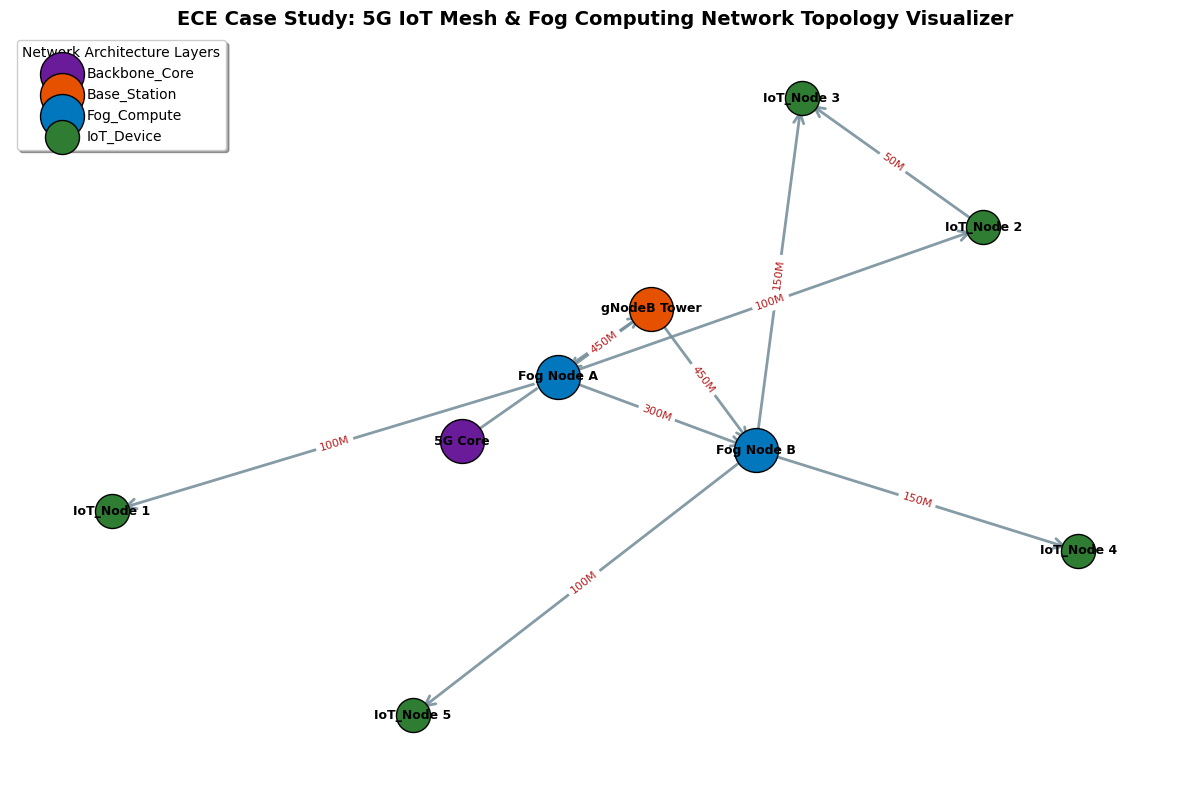

In [10]:
import networkx as nx
import matplotlib.pyplot as plt

# Clear visual layout defaults for high-quality engineering records
plt.style.use('default')

# =====================================================================
# STEP 1: DEFINE ECE CASE STUDY DATA (5G Mesh Network Architecture)
# =====================================================================
# Defining structural hardware nodes and their network layer classes
network_nodes = {
    'Core_Cloud':  {'layer': 'Backbone_Core', 'label': '5G Core'},
    'Base_Station':{'layer': 'Base_Station',  'label': 'gNodeB Tower'},
    'Fog_Node_A':  {'layer': 'Fog_Compute',   'label': 'Fog Node A'},
    'Fog_Node_B':  {'layer': 'Fog_Compute',   'label': 'Fog Node B'},
    'IoT_Edge_1':  {'layer': 'IoT_Device',    'label': 'IoT_Node 1'},
    'IoT_Edge_2':  {'layer': 'IoT_Device',    'label': 'IoT_Node 2'},
    'IoT_Edge_3':  {'layer': 'IoT_Device',    'label': 'IoT_Node 3'},
    'IoT_Edge_4':  {'layer': 'IoT_Device',    'label': 'IoT_Node 4'},
    'IoT_Edge_5':  {'layer': 'IoT_Device',    'label': 'IoT_Node 5'}
}

# Defining directional wireless communication links
# The weights represent link capacity / data throughput capabilities (in Mbps)
communication_links = [
    ('Core_Cloud', 'Base_Station', 1000),   # High-capacity fiber backhaul
    ('Base_Station', 'Fog_Node_A', 450),    # Ultra-wideband wireless link
    ('Base_Station', 'Fog_Node_B', 450),
    ('Fog_Node_A', 'Fog_Node_B', 300),      # Mesh cross-link for redundancy
    ('Fog_Node_A', 'IoT_Edge_1', 100),      # Localised IoT links
    ('Fog_Node_A', 'IoT_Edge_2', 100),
    ('Fog_Node_B', 'IoT_Edge_3', 150),
    ('Fog_Node_B', 'IoT_Edge_4', 150),
    ('Fog_Node_B', 'IoT_Edge_5', 100),
    ('IoT_Edge_2', 'IoT_Edge_3', 50)        # Peer-to-peer (P2P) device mesh hop
]

# =====================================================================
# STEP 2: BUILD TOPOLOGICAL GRAPH OBJECT
# =====================================================================
# Instantiating a Directed Graph (DiGraph matches true asymmetrical network data flows)
G = nx.DiGraph()

# Add nodes with associated layer tags
for node, attrs in network_nodes.items():
    G.add_node(node, **attrs)

# Add links with network capacity values as edge weights
for source, target, throughput in communication_links:
    G.add_edge(source, target, capacity=throughput)

# =====================================================================
# STEP 3: EXECUTE NETWORK PERFORMANCE AUDITS (LAB METRICS)
# =====================================================================
print("--- ECE 5G Mesh Network Topology Analytics ---")
print(f"Total Network Hardware Devices (Nodes): {G.number_of_nodes()}")
print(f"Total Active Physical/Wireless Links (Edges): {G.number_of_edges()}")

# Calculate Betweenness Centrality (Identifies nodes that control traffic flows/bottlenecks)
betweenness = nx.betweenness_centrality(G)
top_routing_hub = max(betweenness, key=betweenness.get)
print(f"Critical Routing Bottleneck Node: {top_routing_hub} (Centrality: {betweenness[top_routing_hub]:.3f})")

# Determine shortest downstream pathway from the core database cloud to a field node
sample_path = nx.shortest_path(G, source='Core_Cloud', target='IoT_Edge_2')
print(f"Optimal Downstream Network Routing Path [Core Cloud -> IoT_Edge_2]: {' -> '.join(sample_path)}")
print("\n" + "="*75 + "\n")

# =====================================================================
# STEP 4: VISUAL GRAPH RENDERING
# =====================================================================
plt.figure(figsize=(12, 8))

# Use a spring layout for clean spacing between nodes
pos = nx.spring_layout(G, seed=15, k=0.9)

# Map colors to structural layers within the communication stack
layer_colors = {
    'Backbone_Core': '#6a1b9a',  # Dark Purple: Core Network Backbone
    'Base_Station': '#e65100',   # Orange: Cellular Macro Base Station (gNodeB)
    'Fog_Compute': '#0277bd',    # Blue: Local Edge Processing Fog Nodes
    'IoT_Device': '#2e7d32'      # Green: Low-power End-User Equipments (UEs)
}

# Plot nodes stratified by layer category
for layer_name, color in layer_colors.items():
    node_list = [n for n, attr in G.nodes(data=True) if attr['layer'] == layer_name]
    nx.draw_networkx_nodes(G, pos, nodelist=node_list, node_color=color,
                           node_size=1000 if layer_name != 'IoT_Device' else 600,
                           edgecolors='black', label=layer_name)

# Plot network directional channel tracks (arrows show data transmission direction)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=18, edge_color='#78909c', width=2.0, alpha=0.9)

# Overlay hardware text tags
node_labels = nx.get_node_attributes(G, 'label')
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=9, font_weight='bold', font_color='black')

# Label data link attributes (Throughput capacity in Mbps)
edge_capacities = nx.get_edge_attributes(G, 'capacity')
formatted_edge_labels = {k: f"{v}M" for k, v in edge_capacities.items()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=formatted_edge_labels, font_size=8, font_color='#b71c1c')

# Layout presentation adjustments
plt.title("ECE Case Study: 5G IoT Mesh & Fog Computing Network Topology Visualizer", fontsize=14, fontweight='bold')
plt.legend(title="Network Architecture Layers", loc="upper left", frameon=True, shadow=True)
plt.axis('off')  # Hide background grid planes
plt.tight_layout()
plt.show()